In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("data_base/cybersecurity_incidents.csv")


--------------------------------------------------------------------------------------------------------------------

##  PANDAS PRACTICE QUESTIONS — CYBERSECURITY DATA

--------------------------------------------------------------------------------------------------------------------



## 1️⃣ Load and Inspect Data  
→ Load the dataset into a Pandas DataFrame and display the first 5 rows.



In [22]:
print(df.head())

  incident_id       date organization     attack_type  severity  data_loss_gb  \
0     INC1000 2023-04-13    CyberGrid      Ransomware    Medium          3.36   
1     INC1001 2024-03-11   DataSecure        Phishing  Critical         21.22   
2     INC1002 2023-09-28     BitGuard      Ransomware    Medium          1.39   
3     INC1003 2023-04-17    CyberGrid  Insider Threat    Medium          5.58   
4     INC1004 2023-03-13     BitGuard         Malware      High          7.17   

   financial_impact_usd  region  detected_by  response_time_hours  resolved  
0              55657.21  Africa  SOC Analyst                 23.1     False  
1              71185.04  Europe  User Report                 70.5      True  
2              54370.83  Europe  SOC Analyst                 13.4      True  
3              19578.63    Asia          IDS                  2.2      True  
4              76233.68  Europe  SOC Analyst                 55.2      True  


## 2️⃣ Filtering and Conditional Selection  
→ Find all incidents where severity is "Critical" and resolved is False.



In [23]:
critical_unresolved = df[
    (df["severity"].str.strip().str.lower() == "critical") &
    (df["resolved"] == False)
]
print(critical_unresolved)

   incident_id       date organization  attack_type  severity  data_loss_gb  \
9      INC1009 2023-08-03    InfoTrust  Brute Force  Critical          5.02   
37     INC1037 2023-07-09    CyberGrid     Phishing  Critical          0.49   
47     INC1047 2023-06-16    CyberTech     Phishing  Critical          5.14   

    financial_impact_usd         region       detected_by  \
9               21739.30  North America               IDS   
37              37175.87  South America  Automated System   
47              76654.96  North America               IDS   

    response_time_hours  resolved  
9                   4.4     False  
37                 44.9     False  
47                 67.5     False  


## 3️⃣ Grouping and Aggregation  
→ Calculate the average financial impact per attack_type.



In [24]:
average_impact = df.groupby("attack_type")[
    "financial_impact_usd"
].mean().sort_values(ascending=False)

print(average_impact)

attack_type
Malware           72257.033333
SQL Injection     61639.137500
Ransomware        59219.802222
Phishing          56603.575000
Brute Force       50455.675833
DDoS              47747.806000
Insider Threat    43440.710000
Name: financial_impact_usd, dtype: float64


## 4️⃣ Sorting and Ranking  
→ List the top 5 incidents with the highest financial impact.



In [25]:
top_5 = df.sort_values(
    by="financial_impact_usd",
    ascending=False
).head(5)

print(top_5)

   incident_id       date organization     attack_type severity  data_loss_gb  \
22     INC1022 2024-01-21   DataSecure      Ransomware   Medium          0.96   
41     INC1041 2023-09-01    CyberGrid         Malware   Medium          2.07   
49     INC1049 2024-01-23   InfoShield  Insider Threat      Low          0.88   
5      INC1005 2023-01-21   SecureWare     Brute Force   Medium          1.36   
11     INC1011 2024-04-03    CyberTech            DDoS     High          0.47   

    financial_impact_usd         region detected_by  response_time_hours  \
22             118360.55         Africa         IDS                 46.2   
41              94073.44  South America         IDS                 49.4   
49              84550.12  South America         IDS                 30.7   
5               83127.64  North America         IDS                 58.3   
11              81709.74         Africa         IDS                 64.0   

    resolved  
22     False  
41      True  
49      Tru

## 5️⃣ Advanced Filtering  
→ Display all incidents that occurred in "Asia" region  
   where attack_type is "Ransomware" and severity is "High".

In [ ]:
asia_ransomware = df[
    (df["region"].str.strip().str.lower() == "asia") &
    (df["attack_type"].str.strip().str.lower() == "ransomware") &
    (df["severity"].str.strip().str.lower() == "high")
]

print(asia_ransomware)



5. ASIA + RANSOMWARE + HIGH SEVERITY
Empty DataFrame
Columns: [incident_id, date, organization, attack_type, severity, data_loss_gb, financial_impact_usd, region, detected_by, response_time_hours, resolved]
Index: []


-----------------------------------------------------------------------------------------------

##  MATPLOTLIB PRACTICE QUESTIONS — VISUALIZATION

---------------------------------------------------------------------------------------------


## 1️⃣ Bar Chart  
→ Plot a bar chart showing the number of incidents per attack_type.



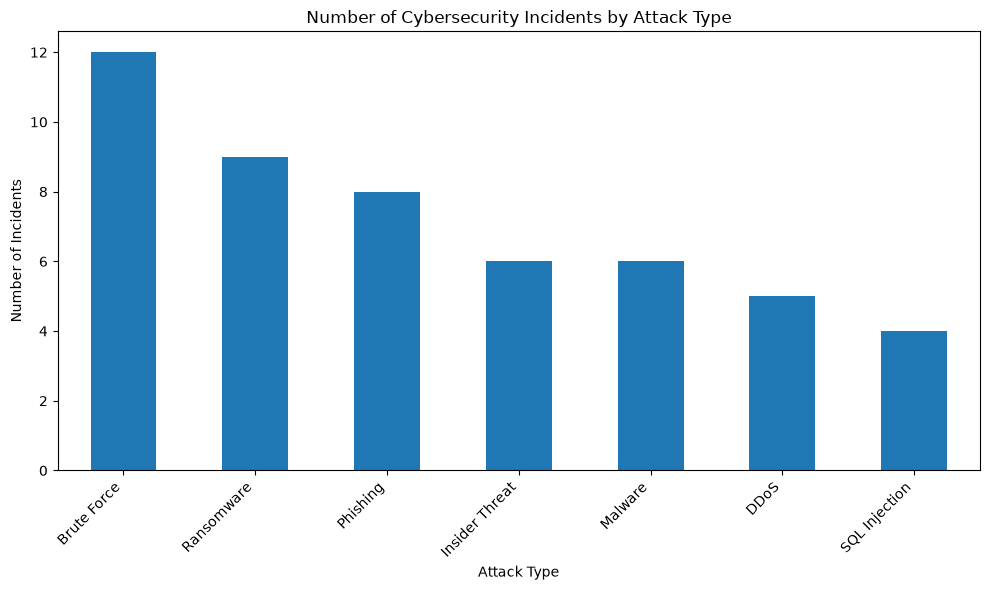

In [17]:

attack_counts = df["attack_type"].value_counts()

plt.figure(figsize=(10, 6))
attack_counts.plot(kind="bar")
plt.title("Number of Cybersecurity Incidents by Attack Type")
plt.xlabel("Attack Type")
plt.ylabel("Number of Incidents")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 2️⃣ Pie Chart  
→ Create a pie chart to visualize the distribution of severity levels.



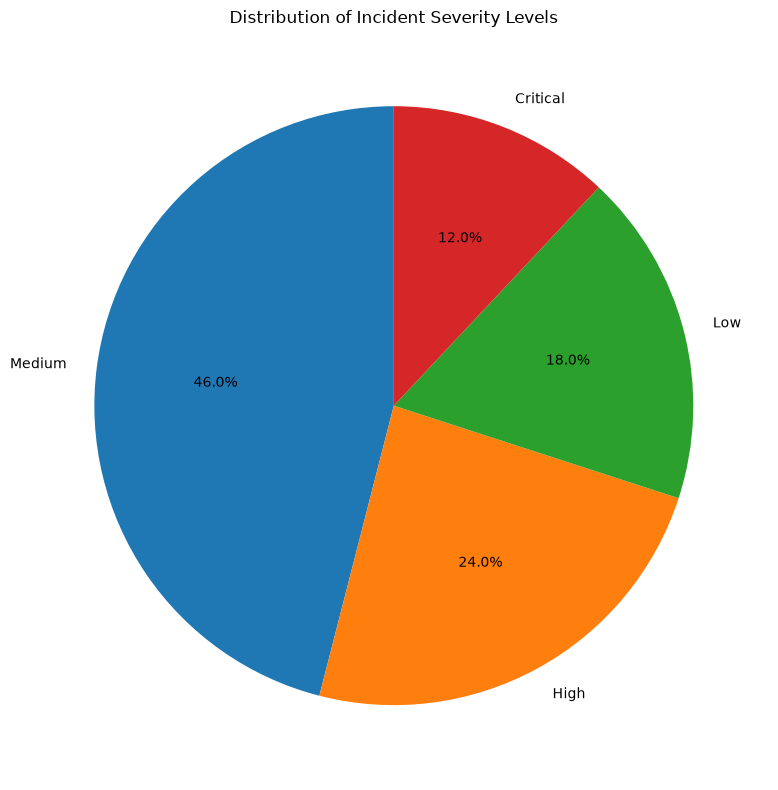

In [16]:

severity_counts = df["severity"].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    severity_counts,
    labels=severity_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Distribution of Incident Severity Levels")
plt.tight_layout()
plt.show()

## 3️⃣ Histogram  
→ Plot a histogram of response_time_hours to visualize the response time distribution.



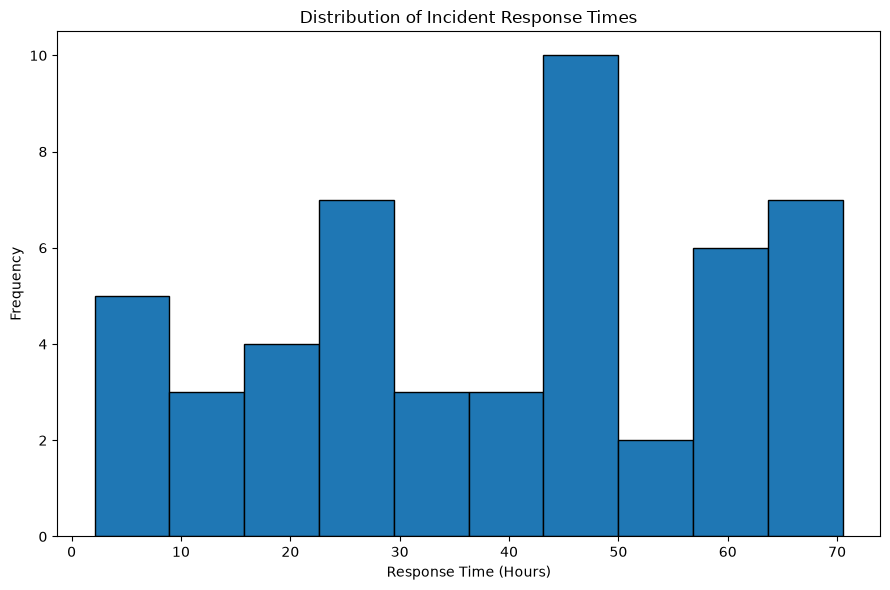

In [19]:
response_times = pd.to_numeric(
    df["response_time_hours"], errors="coerce"
).dropna()

plt.figure(figsize=(9, 6))
plt.hist(response_times, bins=10, edgecolor="black")
plt.title("Distribution of Incident Response Times")
plt.xlabel("Response Time (Hours)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


## 4️⃣ Line Chart  
→ Plot a line chart showing total financial_impact_usd over time (monthly or daily).



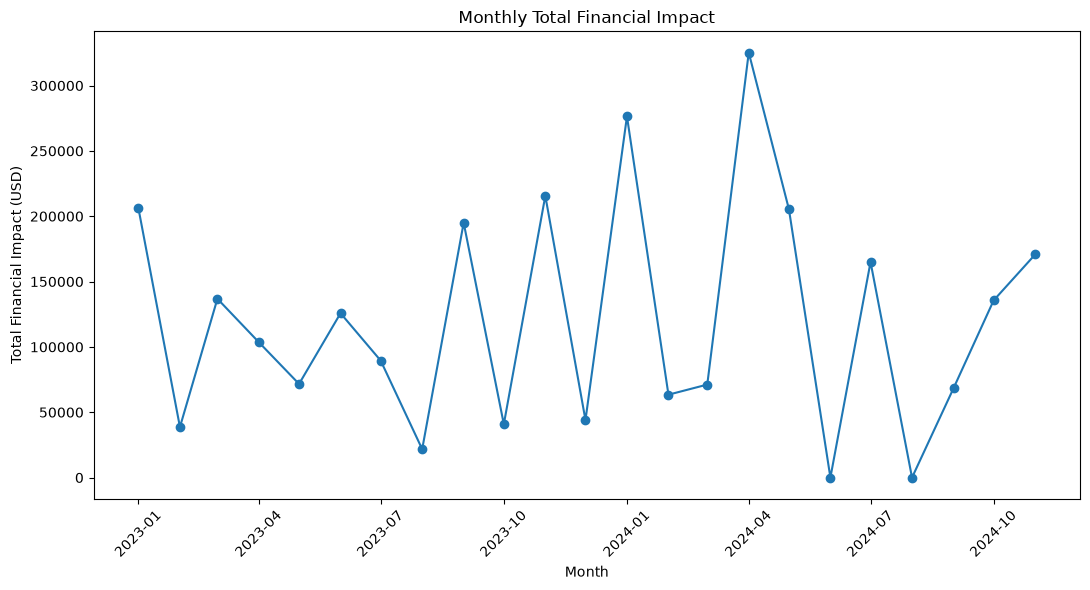

In [20]:
possible_dates = [
    "incident_date", "date", "attack_date",
    "timestamp", "created_at", "reported_date"
]

date_column = next(
    (col for col in possible_dates if col in df.columns),
    None
)

if date_column is not None:
    df[date_column] = pd.to_datetime(
        df[date_column], errors="coerce"
    )

    df["financial_impact_usd"] = pd.to_numeric(
        df["financial_impact_usd"], errors="coerce"
    )

    time_df = df.dropna(
        subset=[date_column, "financial_impact_usd"]
    ).copy()

    if not time_df.empty:
        monthly_impact = (
            time_df.set_index(date_column)["financial_impact_usd"]
            .resample("MS")
            .sum()
        )

        plt.figure(figsize=(11, 6))
        plt.plot(
            monthly_impact.index,
            monthly_impact.values,
            marker="o"
        )
        plt.title("Monthly Total Financial Impact")
        plt.xlabel("Month")
        plt.ylabel("Total Financial Impact (USD)")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
    else:
        print("No valid dates or financial impact values found.")
else:
    print(
        "No recognized date column found. "
        "Check df.columns and update possible_dates."
    )



## 5️⃣ Scatter Plot  
→ Create a scatter plot comparing data_loss_gb (x-axis) and financial_impact_usd (y-axis),  
   colored by severity.

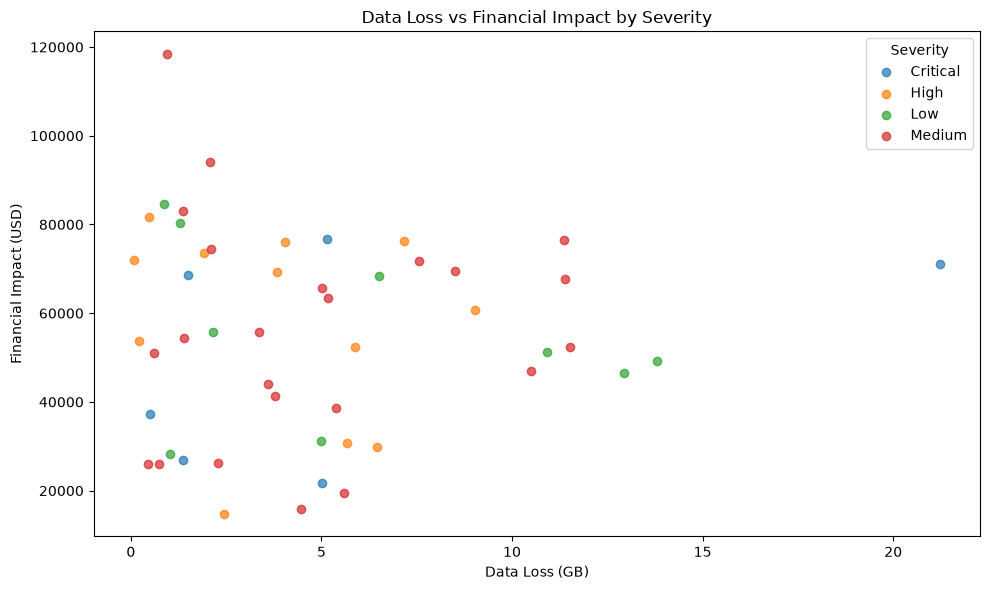

In [21]:
df["data_loss_gb"] = pd.to_numeric(
    df["data_loss_gb"], errors="coerce"
)
df["financial_impact_usd"] = pd.to_numeric(
    df["financial_impact_usd"], errors="coerce"
)

scatter_df = df.dropna(
    subset=[
        "data_loss_gb",
        "financial_impact_usd",
        "severity"
    ]
)

plt.figure(figsize=(10, 6))

for severity, group in scatter_df.groupby("severity"):
    plt.scatter(
        group["data_loss_gb"],
        group["financial_impact_usd"],
        label=severity,
        alpha=0.7
    )

plt.title("Data Loss vs Financial Impact by Severity")
plt.xlabel("Data Loss (GB)")
plt.ylabel("Financial Impact (USD)")
plt.legend(title="Severity")
plt.tight_layout()
plt.show()

